# Using neural networks as encoders

In lecture 16 we fit a neural network. We saw that with tabular data, neural networks do not beat models like random forests or logistic regression.

Neural nets (NN) are good at finding patterns in non-tabular data like images and text. Once a neural net is trained, we can use it to turn images and text into tabular data. Then we fit a regular model on that table.

An **encoder** turns raw data into a row of numbers.

## Setup

In [1]:
library('tidymodels')
library('embed')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   mask

## What is not a table?

Here is one photo, and one sentence:

> "a photo of a dog"

What is a row? What is a column? There is no clear answer. A photo is a grid of pixels. A sentence is a string of words. Neither is **tabular**, where each row is one thing and each column is a named variable.

The models we know (logistic regression, random forests) need a table. So how do we use them on images and text?

 [100%] Downloaded 2366645 bytes...


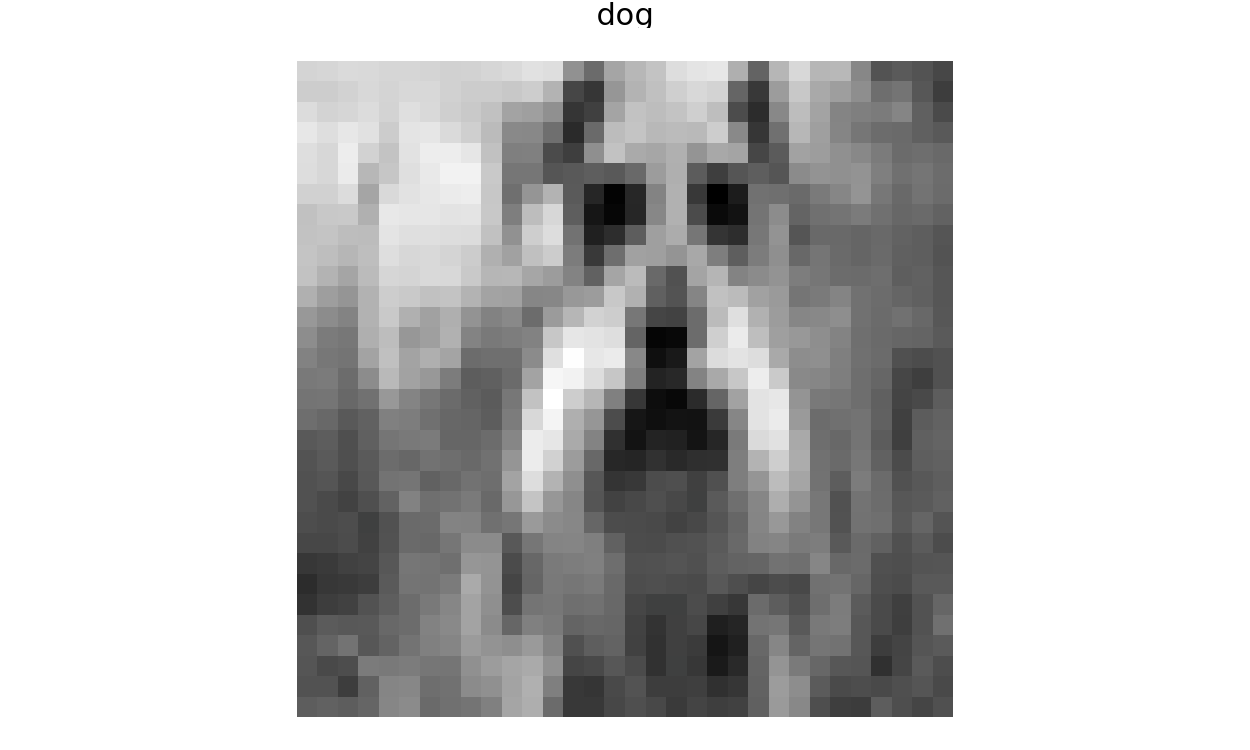

In [2]:
pixels <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/pixels_images.csv.gz', show_col_types = FALSE, progress = FALSE) |>
    mutate(label = factor(label))

# draw photos from rows of the pixel table (one panel per row, titled by `title`)
show_photos <- function(rows) {
    rows |>
        mutate(title = factor(title, levels = unique(title))) |>
        pivot_longer(starts_with('p'), names_to = 'pixel', values_to = 'value') |>
        mutate(
            k = as.integer(sub('p', '', pixel)) - 1,
            x = k %% 32 + 1,
            y = 32 - k %/% 32
        ) |>
        ggplot(aes(x = x, y = y, fill = value)) +
        geom_raster() +
        scale_fill_gradient(low = 'black', high = 'white') +
        coord_equal() +
        facet_wrap(~ title, nrow = 1) +
        theme_void() +
        theme(legend.position = 'none')
}

# row 13 is a dog with a clear face
pixels |> slice(13) |> mutate(title = 'dog') |> show_photos()

## Hidden layers are encoders

Remember the 3 hidden nodes from lecture 16? We computed `node1`, `node2`, and `node3` by hand. Each one was a new column made from `x`.

A hidden layer turns the input into new columns. That is what an **encoder** does. An encoder is a neural net that turns raw data into a row of numbers.

In lecture 16 we trained a tiny one. Today we borrow a big one that someone else already trained.

## How do we train an encoder?

In lecture 16 we trained a net to predict `grass`. We had a label for every person.

Nobody has labeled hundreds of millions of photos with `cat` or `dog`. So encoders learn from a **training task** that needs no hand-made labels. The label comes from the data itself.

Here are three examples:

1. **Match photos with captions (CLIP).** Take a photo and its caption from the web. The net must pick the right caption out of many. Wrong captions are the "negative" examples.
2. **Fill in the blank (language models).** Hide one word in a sentence. The net must guess it.
3. **Same photo, two crops (DINOv2).** Crop one photo two ways. The net must give both crops similar numbers.

To do any of these well, the net has to put similar things close together. That is what we want.

We do not care about the answers to the training task. We keep the numbers from the layer before the answer. Those numbers are the **embedding**.

**The training task is a means to an end. We keep the embedding, not the answers.**

> Aside: [DINOv2](https://ai.meta.com/blog/dinov2-computer-vision-self-supervised-learning/) and [BERT](https://arxiv.org/abs/1810.04805) are two famous encoders. Today we use CLIP for the lecture, and DINOv2 in the exercise.

## A first try: pixels as columns

The simplest idea: make each pixel a column. Our photos are 32 x 32 and gray, so that is 1,024 columns.

Each photo is labeled `cat` or `dog`. Let's pretend we only have **100** labeled photos and fit logistic regression and a random forest.

We have 1,024 columns and 100 rows. Based on lecture 16, what do we expect on new photos?

In [3]:
set.seed(512)

split <- initial_split(pixels, prop = 0.5, strata = label)
train_ids <- training(split)$id
test_ids  <- testing(split)$id

set.seed(3)
small_ids <- sample(train_ids, 100)

accuracy_of <- function(fit, data) {
    mean(predict(fit, new_data = data)$.pred_class == data$label)
}

# fit logistic regression and a random forest on the given table
compare_models <- function(df, ids) {
    train_data <- df |> filter(id %in% ids) |> select(-id)
    test_data  <- df |> filter(id %in% test_ids) |> select(-id)

    fits <- list(
        logistic = logistic_reg(penalty = 0.01, mixture = 0) |> set_engine('glmnet') |>
                       fit(label ~ ., data = train_data),
        forest   = rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger') |>
                       fit(label ~ ., data = train_data)
    )

    tibble(
        model = names(fits),
        train_accuracy = map_dbl(fits, accuracy_of, data = train_data),
        test_accuracy  = map_dbl(fits, accuracy_of, data = test_data)
    )
}

compare_models(pixels, small_ids)

         model    train_accuracy test_accuracy
logistic logistic 0.9            0.533        
forest   forest   1.0            0.540        

## Encode the images

We used a pretrained encoder called **CLIP**. Someone else trained it on hundreds of millions of image and text pairs. We did not train it. We just ran our photos through it.

For each photo, CLIP gives 512 numbers. This list of numbers is called an **embedding**. The 512 columns have no names (`e1`, `e2`, ...). That is OK. We do not need to know what each one means.

Now every photo is a row in a table.

> Aside: CLIP is from OpenAI. [Here is the original post](https://openai.com/index/clip/).

In [8]:
emb <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/embeddings_images.csv.gz', show_col_types = FALSE, progress = FALSE) |>
    mutate(label = factor(label))

dim(emb)

 [100%] Downloaded 1941795 bytes...


[1] 2000  514

In [9]:
emb |> select(1:8) |> head()

  id    label e1     e2      e3      e4      e5     e6     
1  2440 dog   0.0343  0.0024 -0.0184  0.0124 0.0174 -0.0195
2 25260 dog   0.0274  0.0009 -0.0402  0.0125 0.0346 -0.0378
3 11442 dog   0.0220 -0.0099 -0.0392  0.0199 0.0344 -0.0186
4 11351 dog   0.0195  0.0047 -0.0345 -0.0095 0.0118 -0.0319
5 20836 dog   0.0408  0.0017 -0.0304 -0.0017 0.0208 -0.0410
6  1737 cat   0.0176 -0.0014 -0.0222  0.0099 0.0126 -0.0205

## Same 100 images, new columns

Let's use the same 100 training images and the same test images. The only change is the columns: 512 embedding columns instead of 784 pixel columns.

Which will do better on the test set? Let's find out.

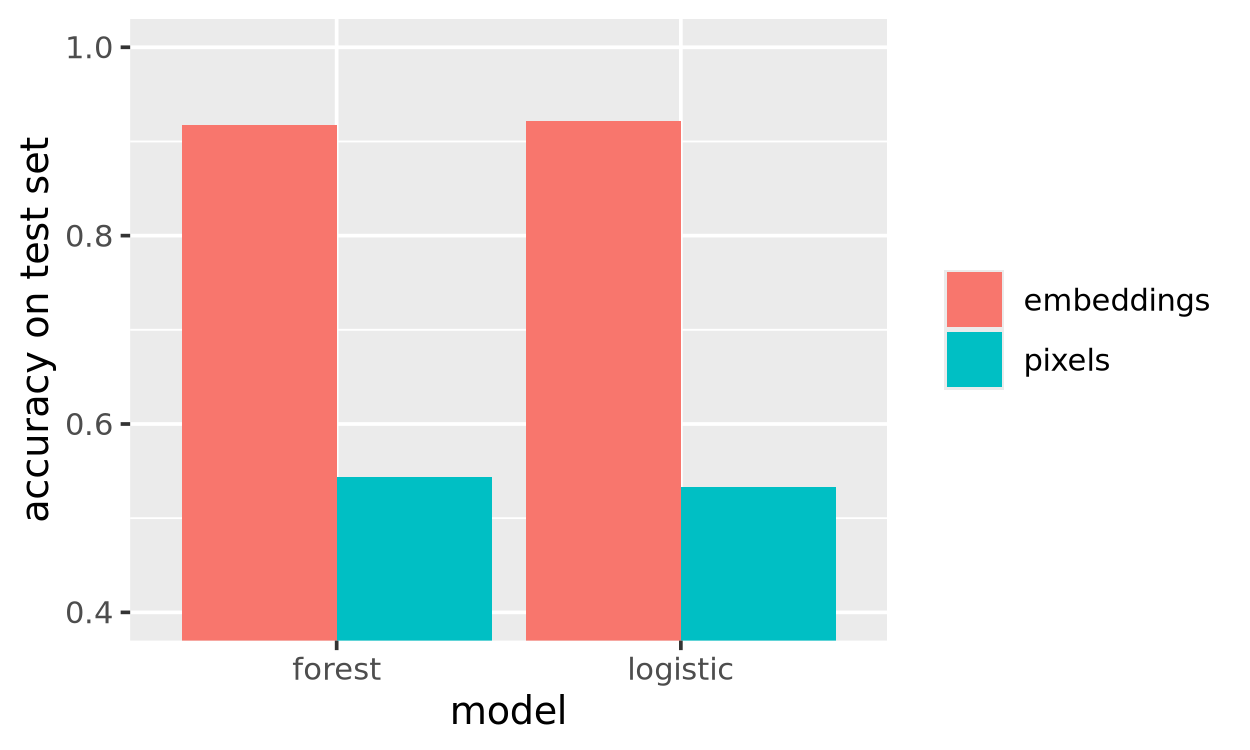

In [5]:
results <- bind_rows(
    compare_models(pixels, small_ids) |> mutate(columns = 'pixels'),
    compare_models(emb, small_ids)    |> mutate(columns = 'embeddings')
)

results

ggplot(results, aes(x = model, y = test_accuracy, fill = columns)) +
    geom_col(position = 'dodge') +
    coord_cartesian(ylim = c(0.4, 1)) +
    labs(fill = NULL, y = 'accuracy on test set')

## Look at the embeddings

512 columns is hard to see. **PCA** squeezes many columns into a few new ones that keep most of the variation. Then we can plot the first two.

If the encoder did a good job, images with the same label will land near each other.

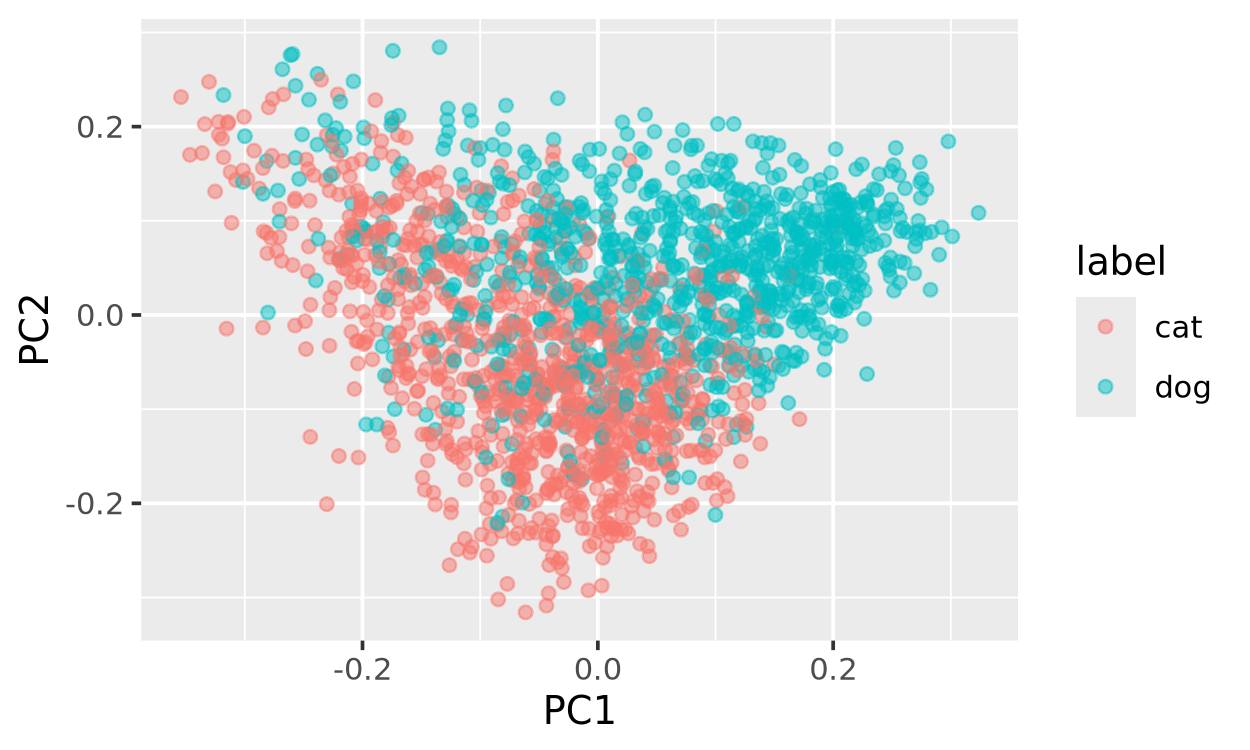

In [6]:
pca <- emb |> select(starts_with('e')) |> prcomp()

pca_df <- as_tibble(pca$x[, 1:2]) |> mutate(label = emb$label)

ggplot(pca_df, aes(x = PC1, y = PC2, color = label)) +
    geom_point(alpha = 0.5)

## UMAP: a better map

PCA can only draw straight lines through the data. **UMAP** can bend. It is another way to squash many columns into 2 while keeping similar rows close.

Let's make a UMAP of the raw pixels, and a UMAP of the embeddings. Both use the same images.

> Aside: [How UMAP works](https://umap-learn.readthedocs.io/en/latest/how_umap_works.html) has nice pictures. Distances between far-apart groups in a UMAP are not meaningful, so don't read too much into them.

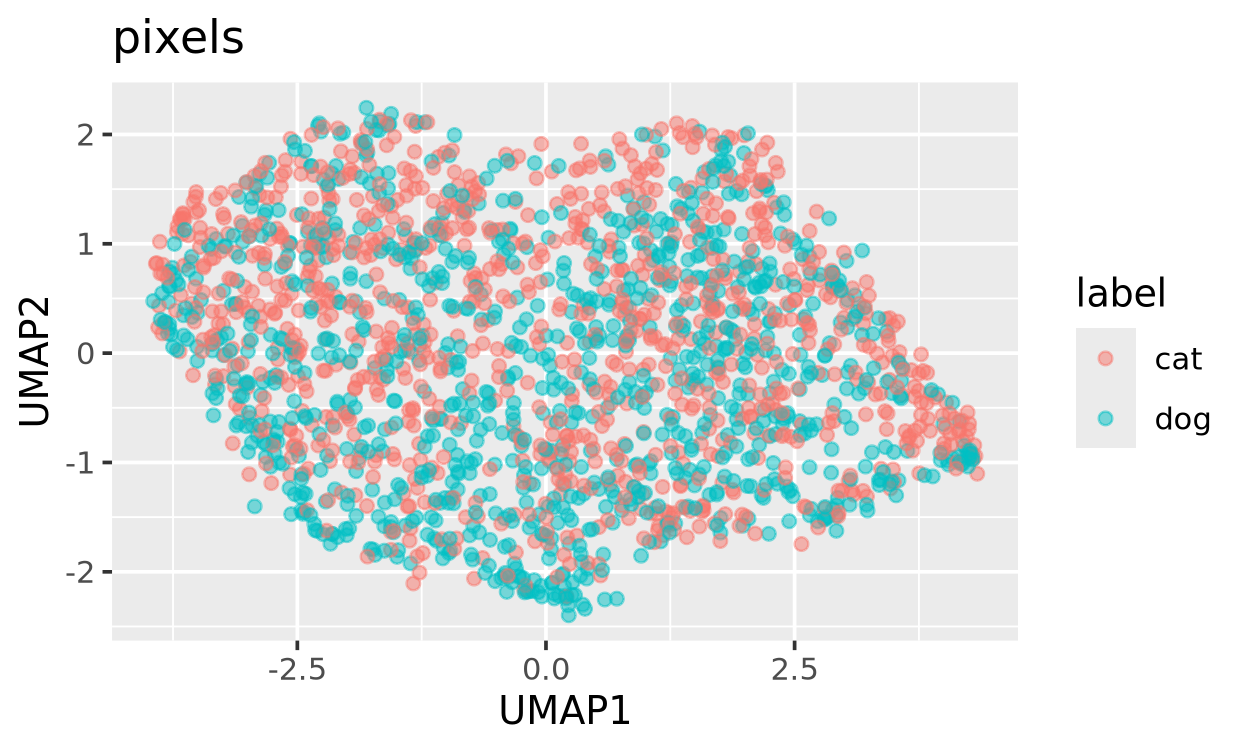

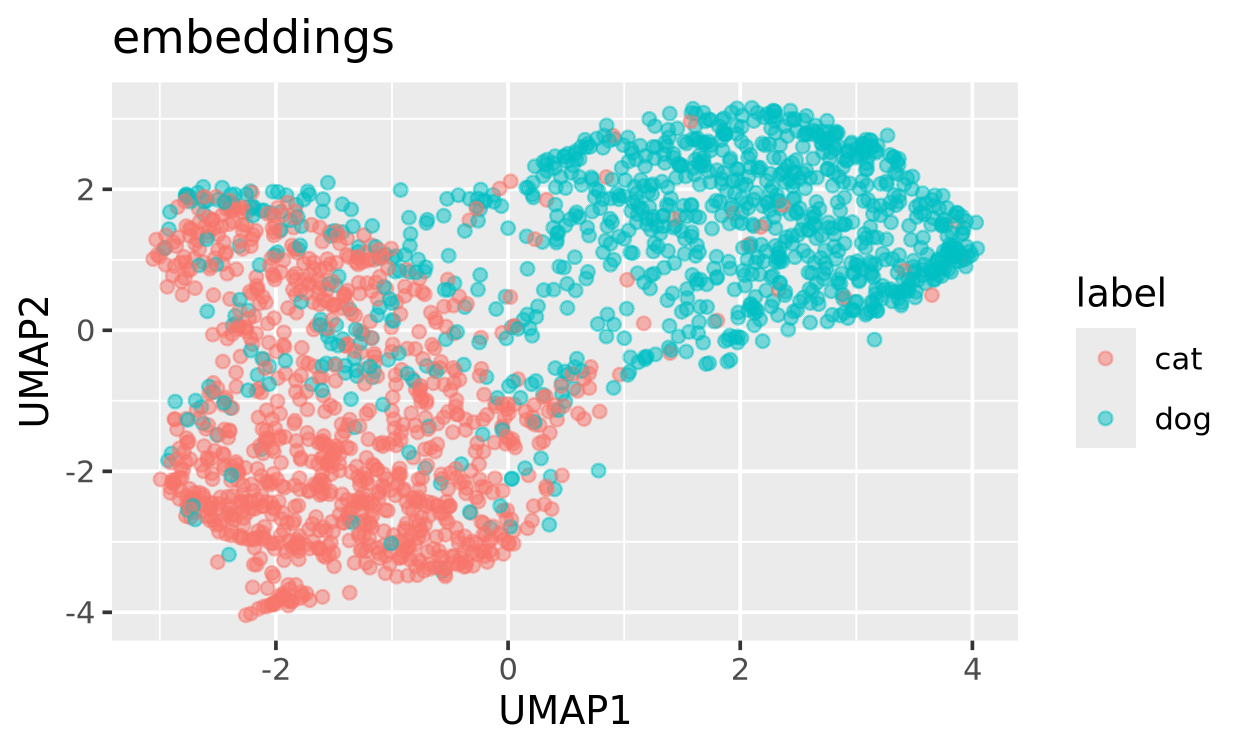

In [10]:
plot_umap <- function(df) {
    set.seed(1)
    coords <- recipe(label ~ ., data = select(df, -id)) |>
        step_umap(all_predictors(), num_comp = 2) |>
        prep() |>
        bake(new_data = NULL)

    ggplot(coords, aes(x = UMAP1, y = UMAP2, color = label)) +
        geom_point(alpha = 0.5)
}

plot_umap(pixels) + labs(title = 'pixels')
plot_umap(emb) + labs(title = 'embeddings')

## Find similar images

Embeddings make a new tool possible: **search**. Two images with similar embeddings are similar.

**Cosine similarity** measures how close two embeddings point in the same direction. 1 means the same direction.

Let's pick one image and find its 5 nearest neighbors.

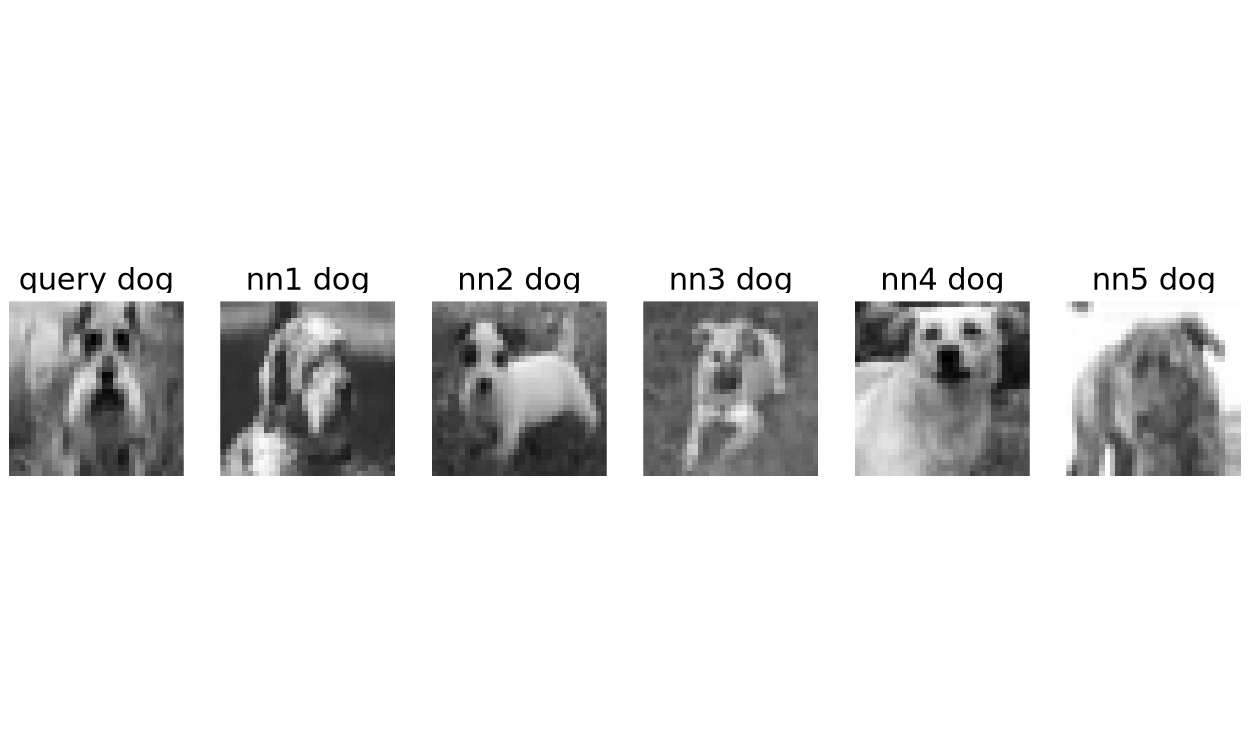

In [11]:
stopifnot(all(pixels$id == emb$id))   # same photos, same row order

E <- emb |> select(starts_with('e')) |> as.matrix()

# every row has length 1, so the dot product is the cosine similarity
cosine_to <- function(i) as.numeric(E %*% E[i, ])

query <- 13
nearest <- order(cosine_to(query), decreasing = TRUE)[1:6]   # the first is the query itself

pixels[nearest, ] |>
    mutate(title = paste(c('query', paste0('nn', 1:5)), label)) |>
    show_photos()

## Zero-shot: no labels at all

CLIP also encodes text, and it puts text and images in the **same space**. So we can compare an image to a sentence.

We encoded two sentences: "a photo of a cat" and "a photo of a dog". For each photo, we pick the sentence with the higher cosine similarity.

We never used a label. How well does this work?

> Aside: this is how CLIP can sort photos into classes it was never trained on.

In [12]:
prompts <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/embeddings_text_prompts.csv')

text_emb <- prompts |> select(starts_with('e')) |> as.matrix()

scores <- E %*% t(text_emb)               # photo vs. each sentence
pred <- prompts$label[max.col(scores)]    # pick the closest sentence

mean(pred == emb$label)
table(predicted = pred, truth = emb$label)

         truth
predicted cat dog
      cat 882  70
      dog 118 930

## Summary

1. An **encoder** turns non-tabular data (images, text) into a table of **embeddings**.
2. The encoder does the hard learning. We fit a small, simple model on top.
3. This helps most when we have **few labels**.
4. Be careful: an encoder can be biased, can be trained on a different kind of data than ours, and could have seen our test data.

**Use a pretrained encoder to turn anything into a table. Then use the models we know.**